In [1]:
# --- IMPORTS & SETUP ---
# Interactive plotting for gate drawing
%matplotlib widget

import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.path as mplPath
from matplotlib.widgets import PolygonSelector
import FlowCal

plt.style.use('seaborn-v0_8-whitegrid')

gate_filename = r"C:\Users\music\OneDrive\Desktop\CompLab\SynAD\data\Universal\flowgates_A7_incfluorescence_ICAM1.pkl"

# --- HELPER FUNCTION: Apply Gate ---
def apply_gate(flow_data, vertices, channels):
    """Filters FlowCal data based on polygon vertices."""
    if not vertices:
        return flow_data
    
    # Extract data for the specific channels
    points = np.column_stack((flow_data[:, channels[0]], flow_data[:, channels[1]]))
    
    # Create mask
    path = mplPath.Path(vertices)
    mask = path.contains_points(points)
    
    return flow_data[mask]

# --- HELPER FUNCTION: Extract Channel Mapping --- (specific to Nunez machine)
NUNEZ_MAPPING = {
    'BB515-A': 'GFP',
    'BV421-A': 'BFP', 
    'PE-CF594-A': 'RFP'
}

def extract_channel_mapping(fcs_file_path, expected_mapping=NUNEZ_MAPPING):
    """
    Applies a strict channel mapping for the specific instrument.
    """
    fcs_data = FlowCal.io.FCSData(fcs_file_path)
    available_channels = fcs_data.channels
    
    # Validate that all expected channels actually exist in the FCS file
    missing_channels = [ch for ch in expected_mapping.keys() if ch not in available_channels]
    
    if missing_channels:
        raise ValueError(f"Expected channels missing from FCS file '{fcs_file_path}': {missing_channels}. Available channels are: {available_channels}")
    
    return expected_mapping

# --- HELPER FUNCTION: Save Gates ---
def save_gates(filename, gate_dict):
    """Save gate dictionary to pickle file."""
    with open(filename, "wb") as f:
        pickle.dump(gate_dict, f)
    print(f"Gates saved to {filename}")

# --- LOAD SETUP FILE ---
setup_file_path = r"I:\Shared drives\StallerLabSPA\Projects\Marissa\SyntheticADs\Izaiah_Flow_Data\20260521_ICAM1_SynADs_2d\Specimen_001_A7_A07.fcs"
s1 = FlowCal.io.FCSData(setup_file_path)
print(f"Loaded setup file: {os.path.basename(setup_file_path)} with {s1.shape[0]} events.")

# Initialize empty gate dictionary
active_gates = {}
print("Ready to draw gates interactively.")

Loaded setup file: Specimen_001_A7_A07.fcs with 10000 events.
Ready to draw gates interactively.


Draw your live gate now. Press ENTER when finished.


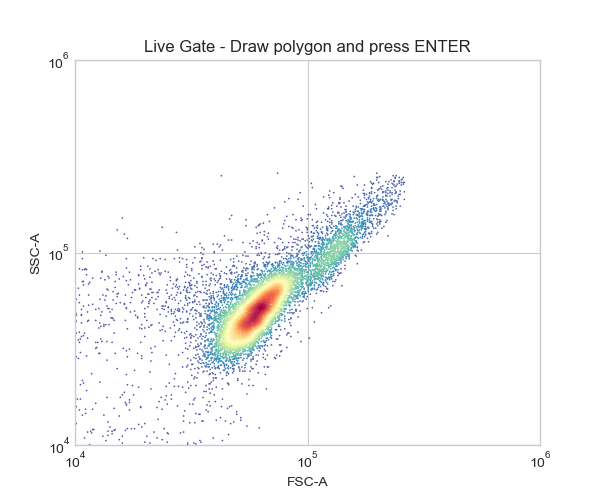

In [3]:
# --- DRAW LIVE GATE ---
live_channels = ['FSC-A', 'SSC-A']

fig, ax = plt.subplots(figsize=(6, 5))
FlowCal.plot.density2d(s1, channels=live_channels, mode='scatter', sigma=5)
plt.xscale('log'); plt.yscale('log')
plt.xlim(1e4, 1e6); plt.ylim(1e4, 1e6)
plt.title("Live Gate - Draw polygon and press ENTER")

print("Draw your live gate now. Press ENTER when finished.")

def on_select_live(verts):
    active_gates['live'] = verts
    print(f"Live Gate captured: {len(verts)} vertices")

selector_live = PolygonSelector(ax, on_select_live, props=dict(color='red', linewidth=2))
plt.show()

Live-gated data: 6435 events
Draw your singles gate now. Press ENTER when finished.


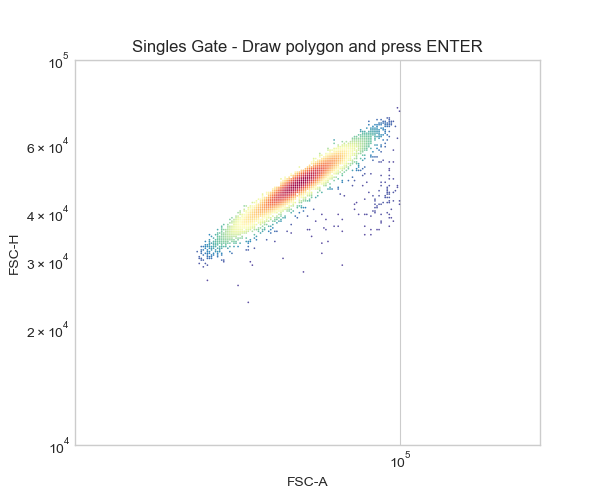

In [4]:
# --- DRAW SINGLES GATE ---
# Apply Live Gate first
live_channels = ['FSC-A', 'SSC-A']
s1_live = apply_gate(s1, active_gates.get('live'), live_channels)

if s1_live.shape[0] == 0:
    raise ValueError("Live gate is empty. Halting execution. Please redraw the live gate.")

print(f"Live-gated data: {s1_live.shape[0]} events")
    
# Define Channels for singles gate
singles_channels = ['FSC-A', 'FSC-H']

# Setup Plot
fig, ax = plt.subplots(figsize=(6, 5))
FlowCal.plot.density2d(s1_live, channels=singles_channels, mode='scatter', sigma=5)
plt.xscale('log'); plt.yscale('log')
plt.xlim(2e4, 2e5); plt.ylim(1e4, 1e5)
plt.title("Singles Gate - Draw polygon and press ENTER")

print("Draw your singles gate now. Press ENTER when finished.")
    
def on_select_singles(verts):
    active_gates['singles'] = verts
    print(f"Singles Gate captured: {len(verts)} vertices")

selector_singles = PolygonSelector(ax, on_select_singles, props=dict(color='red', linewidth=2))
plt.show()

In [6]:
# --- APPLY GATES FOR FLUORESCENCE DRAWING ---
# Generate the fully gated population (Live + Singles) to use for the next three gates
s1_singles = apply_gate(s1_live, active_gates.get('singles'), singles_channels)

if s1_singles.shape[0] == 0:
    raise ValueError("Singles gate is empty. Halting execution. Please redraw the singles gate.")

print(f"Single-cell gated data: {s1_singles.shape[0]} events")
total_singles = s1_singles.shape[0]

Single-cell gated data: 6216 events


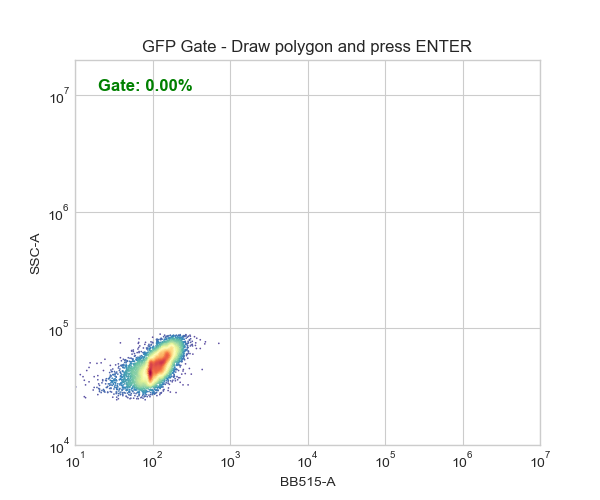

In [7]:
# --- DRAW GFP GATE ---
gfp_channels = ['BB515-A', 'SSC-A']
points_gfp = np.column_stack((s1_singles[:, gfp_channels[0]], s1_singles[:, gfp_channels[1]]))

fig, ax = plt.subplots(figsize=(6, 5))
FlowCal.plot.density2d(s1_singles, channels=gfp_channels, mode='scatter', sigma=5)
plt.xscale('log'); plt.yscale('log')
plt.xlim(1e1, 1e7); plt.ylim(1e4, 2e7)

plt.title("GFP Gate - Draw polygon and press ENTER")

# Create a text annotation on the plot
gfp_text = ax.text(0.05, 0.95, 'Gate: 0.00%', transform=ax.transAxes, 
                   va='top', fontsize=12, color='green', fontweight='bold')

def on_select_gfp(verts):
    active_gates['gfp'] = verts
    
    # Calculate percentage dynamically
    path = mplPath.Path(verts)
    mask = path.contains_points(points_gfp)
    pct = (np.sum(mask) / total_singles) * 100
    
    # Update text and redraw canvas
    gfp_text.set_text(f"Gate: {pct:.2f}% ({np.sum(mask)} cells)")
    fig.canvas.draw_idle()

selector_gfp = PolygonSelector(ax, on_select_gfp, props=dict(color='green', linewidth=2))
plt.show()

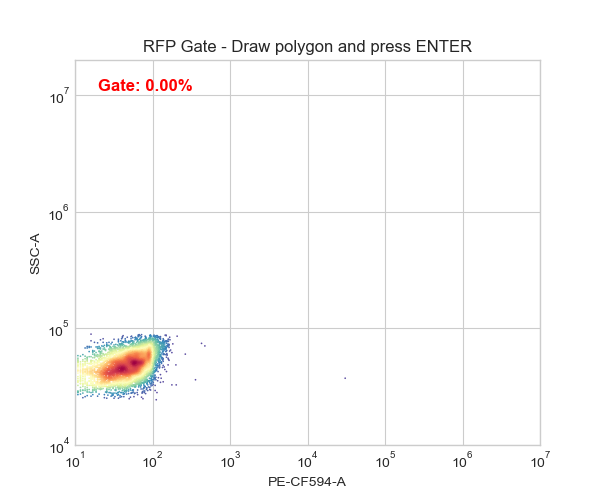

In [8]:
# --- DRAW RFP GATE ---
rfp_channels = ['PE-CF594-A', 'SSC-A']
points_rfp = np.column_stack((s1_singles[:, rfp_channels[0]], s1_singles[:, rfp_channels[1]]))

fig, ax = plt.subplots(figsize=(6, 5))
FlowCal.plot.density2d(s1_singles, channels=rfp_channels, mode='scatter', sigma=5)
plt.xscale('log'); plt.yscale('log')
plt.xlim(1e1, 1e7); plt.ylim(1e4, 2e7)

plt.title("RFP Gate - Draw polygon and press ENTER")

rfp_text = ax.text(0.05, 0.95, 'Gate: 0.00%', transform=ax.transAxes, 
                   va='top', fontsize=12, color='red', fontweight='bold')

def on_select_rfp(verts):
    active_gates['rfp'] = verts
    path = mplPath.Path(verts)
    mask = path.contains_points(points_rfp)
    pct = (np.sum(mask) / total_singles) * 100
    
    rfp_text.set_text(f"Gate: {pct:.2f}% ({np.sum(mask)} cells)")
    fig.canvas.draw_idle()

selector_rfp = PolygonSelector(ax, on_select_rfp, props=dict(color='red', linewidth=2))
plt.show()

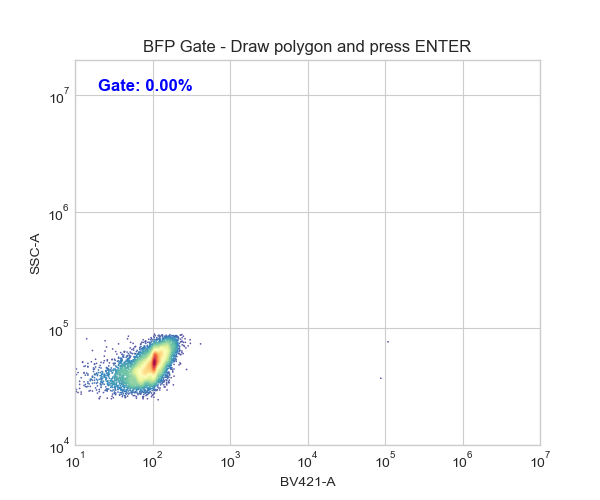

In [9]:
# --- DRAW BFP GATE ---
bfp_channels = ['BV421-A', 'SSC-A']
points_bfp = np.column_stack((s1_singles[:, bfp_channels[0]], s1_singles[:, bfp_channels[1]]))

fig, ax = plt.subplots(figsize=(6, 5))
FlowCal.plot.density2d(s1_singles, channels=bfp_channels, mode='scatter', sigma=5)
plt.xscale('log'); plt.yscale('log')
plt.xlim(1e1, 1e7); plt.ylim(1e4, 2e7)

plt.title("BFP Gate - Draw polygon and press ENTER")

bfp_text = ax.text(0.05, 0.95, 'Gate: 0.00%', transform=ax.transAxes, 
                   va='top', fontsize=12, color='blue', fontweight='bold')

def on_select_bfp(verts):
    active_gates['bfp'] = verts
    path = mplPath.Path(verts)
    mask = path.contains_points(points_bfp)
    pct = (np.sum(mask) / total_singles) * 100
    
    bfp_text.set_text(f"Gate: {pct:.2f}% ({np.sum(mask)} cells)")
    fig.canvas.draw_idle()

selector_bfp = PolygonSelector(ax, on_select_bfp, props=dict(color='blue', linewidth=2))
plt.show()

In [10]:
# --- EXTRACT CHANNEL MAPPING AND SAVE ---

# 1. Validate gates were drawn
missing_gates = []
required_gates = ['live', 'singles', 'gfp', 'rfp', 'bfp']

for gate_name in required_gates:
    if gate_name not in active_gates or not active_gates[gate_name]:
        missing_gates.append(gate_name)

if missing_gates:
    # Strictly halt execution if any gates are missing to prevent saving incomplete data
    raise ValueError(f"Missing gates: {missing_gates}. Please draw all gates before saving.")

In [11]:
# 2. Extract and validate channel mapping
print("\n--- Validating Channel Metadata ---")
channel_mapping = extract_channel_mapping(setup_file_path)

# 3. Preview the mapping
print(f"Validated {len(channel_mapping)} expected channels:")
for short_name, user_desc in sorted(channel_mapping.items()):
    print(f"  {short_name:10s} -> {user_desc}")


--- Validating Channel Metadata ---
Validated 3 expected channels:
  BB515-A    -> GFP
  BV421-A    -> BFP
  PE-CF594-A -> RFP


In [12]:
# 4. Package everything for saving
gate_data = {
    'live': active_gates['live'],
    'singles': active_gates['singles'],
    'gfp': active_gates['gfp'],
    'rfp': active_gates['rfp'],
    'bfp': active_gates['bfp'],
    'channel_mapping': channel_mapping
}

# 5. Save to pickle
print(f"\n--- Saving to {os.path.basename(gate_filename)} ---")
save_gates(gate_filename, gate_data)
print(f"Saved {len(required_gates)} gates and {len(channel_mapping)} channel mappings.")


--- Saving to flowgates_A7_incfluorescence_ICAM1.pkl ---
Gates saved to C:\Users\music\OneDrive\Desktop\CompLab\SynAD\data\Universal\flowgates_A7_incfluorescence_ICAM1.pkl
Saved 5 gates and 3 channel mappings.
